# PHÂN TÍCH DỮ LIỆU BÁN HÀNG TRỰC TUYẾN BẰNG PYTHON

# **1. Giới thiệu đề tài**


Trong bối cảnh thương mại điện tử ngày càng phát triển, dữ liệu bán hàng đóng vai trò quan trọng trong việc giúp doanh nghiệp hiểu rõ tình hình kinh doanh và hành vi mua sắm của khách hàng. Việc phân tích dữ liệu giúp doanh nghiệp xác định xu hướng doanh thu, sản phẩm có hiệu quả cao và thị trường tiềm năng.

Đề tài này sử dụng Python để khám phá, xử lý và phân tích dữ liệu bán hàng trực tuyến từ bộ dữ liệu Online Retail II.

# **2. Mục tiêu**


Khám phá cấu trúc và đặc điểm của dữ liệu bán hàng.

Kiểm tra và làm sạch dữ liệu thiếu, dữ liệu trùng và dữ liệu bất thường.

Phân tích doanh thu, sản phẩm, khách hàng và thị trường.

Trực quan hóa dữ liệu bằng biểu đồ.

Rút ra ít nhất ba nhận xét có ý nghĩa từ kết quả phân tích.


#**3. Công cụ sử dụng**

Python, Pandas, NumPy ,Matplotlib và Seaborn .

# **4. Nguồn dữ liệu**


Tên bộ dữ liệu: [Online Retail II](https://archive.ics.uci.edu/dataset/502/online+retail+ii).

Nguồn: UCI Machine Learning Repository.\
Lĩnh vực: Bán hàng .\
Số lượng dữ liệu: hơn 1 triệu bản ghi .\
Nội dung: dữ liệu giao dịch bán hàng trực tuyến .\
Số thuộc tính: 8 .
* Invoice	: Mã hóa đơn
* StockCode	: Mã sản phẩm
* Description	: Tên hoặc mô tả sản phẩm
* Quantity: Số lượng
* InvoiceDate : Ngày giờ giao dịch
* Price	: Đơn giá
* Customer : ID	Mã khách hàng
* Country	: Quốc gia của giao dịch

# **5. Nhập thư viện**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as ticker



#**6. Đọc dữ liệu**

In [ ]:
sheets = pd.read_excel(
    "online_retail_II.xlsx",
    sheet_name=None
)

df = pd.concat(sheets.values(), ignore_index=True)

print("Số dòng dữ liệu:", df.shape[0])
print("Số cột dữ liệu:", df.shape[1])

print("\n5 dòng dữ liệu đầu tiên:")
display(df.head())

Số dòng dữ liệu: 1067371
Số cột dữ liệu: 8

5 dòng dữ liệu đầu tiên:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


# **7. Thông tin của dữ liệu**


In [ ]:
print("Danh sách các cột:")
print(df.columns.tolist())

print("\nThông tin tổng quan:")
df.info()

print("\nThống kê mô tả:")
display(df.describe())

Danh sách các cột:
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']

Thông tin tổng quan:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[ns]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 65.1+ MB

Thống kê mô tả:


,Quantity,InvoiceDate,Price,Customer ID
count,1.067371e+06,1067371,1.067371e+06,824364.000000
mean,9.938898e+00,2011-01-02 21:13:55.394028544,4.649388e+00,15324.638504
min,-8.099500e+04,2009-12-01 07:45:00,-5.359436e+04,12346.000000
25%,1.000000e+00,2010-07-09 09:46:00,1.250000e+00,13975.000000
50%,3.000000e+00,2010-12-07 15:28:00,2.100000e+00,15255.000000
75%,1.000000e+01,2011-07-22 10:23:00,4.150000e+00,16797.000000
max,8.099500e+04,2011-12-09 12:50:00,3.897000e+04,18287.000000
std,1.727058e+02,NaN,1.235531e+02,1697.464450


#**8.Kiểm tra và làm sạch dữ liệu**

**8.1. Kiểm tra dữ liệu thiếu (Missing Values)**

In [ ]:
missing_values = df.isnull().sum()

missing_percent = (df.isnull().sum() / len(df)) * 100

missing_table = pd.DataFrame({
    "Số giá trị thiếu": missing_values,
    "Tỷ lệ thiếu (%)": missing_percent.round(2)
})

print("BẢNG KIỂM TRA DỮ LIỆU THIẾU:")
display(missing_table)

BẢNG KIỂM TRA DỮ LIỆU THIẾU:


,Số giá trị thiếu,Tỷ lệ thiếu (%)
Invoice,0,0.00
StockCode,0,0.00
Description,4382,0.41
Quantity,0,0.00
InvoiceDate,0,0.00
Price,0,0.00
Customer ID,243007,22.77
Country,0,0.00


**8.2. Kiểm tra dữ liệu trùng lặp (Duplicate Values)**

In [ ]:
duplicate_count = df.duplicated().sum()

print("Tổng số dòng dữ liệu:", len(df))
print("Số dòng bị trùng lặp:", duplicate_count)

duplicate_percent = duplicate_count / len(df) * 100

print("Tỷ lệ trùng lặp: {:.2f}%".format(duplicate_percent))

Tổng số dòng dữ liệu: 1067371
Số dòng bị trùng lặp: 34335
Tỷ lệ trùng lặp: 3.22%


**8.3. Kiểm tra dữ liệu bất thường (Abnormal Values)**

---
Đối với dữ liệu bán hàng, hai thuộc tính quan trọng là Quantity (số lượng sản phẩm) và Price (đơn giá). Cần kiểm tra các giá trị bằng 0 hoặc âm để xác định những giao dịch không phù hợp với việc tính doanh thu bán hàng thông thường.

Ngoài ra, bộ dữ liệu Online Retail II có thể chứa các hóa đơn hủy, được nhận diện bằng mã hóa đơn bắt đầu bằng ký tự C.


In [ ]:
print("Số dòng có Quantity <= 0:",
      (df["Quantity"] <= 0).sum())

print("Số dòng có Price <= 0:",
      (df["Price"] <= 0).sum())

cancelled = df["Invoice"].astype(str).str.startswith("C")

print("Số dòng thuộc hóa đơn hủy:",
      cancelled.sum())

display(df[["Quantity", "Price"]].describe())

Số dòng có Quantity <= 0: 22950
Số dòng có Price <= 0: 6207
Số dòng thuộc hóa đơn hủy: 19494


,Quantity,Price
count,1.067371e+06,1.067371e+06
mean,9.938898e+00,4.649388e+00
std,1.727058e+02,1.235531e+02
min,-8.099500e+04,-5.359436e+04
25%,1.000000e+00,1.250000e+00
50%,3.000000e+00,2.100000e+00
75%,1.000000e+01,4.150000e+00
max,8.099500e+04,3.897000e+04


**8.4. Xử lý và làm sạch dữ liệu**

---
Sau khi kiểm tra chất lượng dữ liệu, tiến hành làm sạch nhằm chuẩn bị dữ liệu cho quá trình phân tích doanh thu và hoạt động bán hàng.

Các quy tắc xử lý được áp dụng như sau:


1. Dữ liệu trùng lặp: Loại bỏ các dòng trùng lặp hoàn toàn để hạn chế việc tính lặp giao dịch.

2. Hóa đơn hủy: Loại bỏ các dòng thuộc hóa đơn có mã bắt đầu bằng ký tự C khỏi dữ liệu phân tích doanh thu bán hàng.

3. Số lượng và đơn giá: Chỉ giữ những dòng có Quantity > 0 và Price > 0.

4. Tên sản phẩm: Loại bỏ các dòng thiếu Description để đảm bảo dữ liệu phục vụ phân tích sản phẩm.

5. Mã khách hàng: Giữ lại các giao dịch thiếu Customer ID trong phân tích doanh thu chung. Khi phân tích theo từng khách hàng, chỉ sử dụng các giao dịch có mã khách hàng.

Dữ liệu gốc được giữ nguyên trong biến df; dữ liệu sau làm sạch được lưu trong biến df_clean để sử dụng cho các bước phân tích tiếp theo.


In [ ]:
df_clean = df.copy()

df_clean = df_clean.drop_duplicates()

df_clean = df_clean[
    ~df_clean["Invoice"].astype(str).str.startswith("C")
].copy()

df_clean = df_clean[
    (df_clean["Quantity"] > 0) &
    (df_clean["Price"] > 0)
].copy()

df_clean = df_clean.dropna(subset=["Description"])

df_clean["Description"] = (
    df_clean["Description"].astype(str).str.strip()
)

df_clean = df_clean[
    df_clean["Description"] != ""
].copy()

df_clean["Revenue"] = (
    df_clean["Quantity"] * df_clean["Price"]
)

df_clean = df_clean.reset_index(drop=True)

print("Đã làm sạch dữ liệu thành công!")
display(df_clean.head())

Đã làm sạch dữ liệu thành công!


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,30.0


**8.5 So sánh dữ liệu trước và sau**

In [ ]:

so_dong_ban_dau = len(df)
so_dong_sau_lam_sach = len(df_clean)
so_dong_da_loai = so_dong_ban_dau - so_dong_sau_lam_sach

ty_le_giu_lai = (
    so_dong_sau_lam_sach / so_dong_ban_dau * 100
)

comparison = pd.DataFrame({
    "Chỉ tiêu": [
        "Số dòng ban đầu",
        "Số dòng sau làm sạch",
        "Số dòng đã loại bỏ",
        "Tỷ lệ dữ liệu giữ lại (%)"
    ],
    "Giá trị": [
        so_dong_ban_dau,
        so_dong_sau_lam_sach,
        so_dong_da_loai,
        round(ty_le_giu_lai, 2)
    ]
})

display(comparison)

print("Số dòng trùng lặp còn lại:",
      df_clean.duplicated().sum())

print("Số dòng có Quantity <= 0:",
      (df_clean["Quantity"] <= 0).sum())

print("Số dòng có Price <= 0:",
      (df_clean["Price"] <= 0).sum())

print("Số dòng thiếu Description:",
      df_clean["Description"].isnull().sum())

,Chỉ tiêu,Giá trị
0,Số dòng ban đầu,1067371.00
1,Số dòng sau làm sạch,1007913.00
2,Số dòng đã loại bỏ,59458.00
3,Tỷ lệ dữ liệu giữ lại (%),94.43


Số dòng trùng lặp còn lại: 0
Số dòng có Quantity <= 0: 0
Số dòng có Price <= 0: 0
Số dòng thiếu Description: 0


**8.6. Xuất dữ liệu sau khi làm sạch**

In [ ]:
df_clean.to_csv(
    "online_retail_clean.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Đã xuất file dữ liệu sạch thành công!")
print("Tên file: online_retail_clean.csv")
print("Số dòng:", len(df_clean))
print("Số cột:", len(df_clean.columns))

Đã xuất file dữ liệu sạch thành công!
Tên file: online_retail_clean.csv
Số dòng: 1007913
Số cột: 10


# **9. Phân tích**

Trong quá trình phân tích dữ liệu bán hàng, đề tài đã áp dụng các phương pháp xử lý dữ liệu bằng thư viện Pandas, bao gồm:

1. Nhóm dữ liệu (groupby) theo tháng, sản phẩm, khách hàng và quốc gia.

2. Lọc dữ liệu để lựa chọn các giao dịch hợp lệ và các giao dịch có mã khách hàng.

3. Sắp xếp dữ liệu (sort_values) nhằm xác định những sản phẩm, khách hàng và thị trường có doanh thu cao nhất.

4. Tổng hợp dữ liệu (sum, agg, nunique) để tính doanh thu, số lượng sản phẩm, số hóa đơn và số khách hàng.

**9.1. Phân tích tổng quan hoạt động bán hàng**

---
Mục tiêu của phân tích này là đánh giá quy mô hoạt động bán hàng dựa trên dữ liệu đã được làm sạch.

Các chỉ tiêu được sử dụng gồm:

1. Tổng doanh thu bán hàng.

2. Tổng số hóa đơn bán hàng.

3. Tổng số lượng sản phẩm đã bán.

4. Số lượng mã sản phẩm khác nhau.

5. Số lượng khách hàng có mã định danh.

Các chỉ tiêu này cung cấp cái nhìn tổng quan về quy mô kinh doanh trong khoảng thời gian của bộ dữ liệu.




In [ ]:

tong_doanh_thu = df_clean["Revenue"].sum()

tong_hoa_don = df_clean["Invoice"].nunique()

tong_san_pham_ban = df_clean["Quantity"].sum()

so_loai_san_pham = df_clean["StockCode"].nunique()

so_khach_hang = df_clean["Customer ID"].nunique()

tong_quan = pd.DataFrame({
    "Chỉ tiêu": [
        "Tổng doanh thu",
        "Tổng số hóa đơn",
        "Tổng số lượng sản phẩm bán ra",
        "Số mã sản phẩm khác nhau",
        "Số khách hàng có mã định danh"
    ],
    "Giá trị": [
        f"{tong_doanh_thu:,.2f}",
        f"{tong_hoa_don:,}",
        f"{tong_san_pham_ban:,}",
        f"{so_loai_san_pham:,}",
        f"{so_khach_hang:,}"
    ]
})

print("BẢNG TỔNG QUAN HOẠT ĐỘNG BÁN HÀNG")
display(tong_quan)

BẢNG TỔNG QUAN HOẠT ĐỘNG BÁN HÀNG


,Chỉ tiêu,Giá trị
0,Tổng doanh thu,"20,476,260.45"
1,Tổng số hóa đơn,"40,077"
2,Tổng số lượng sản phẩm bán ra,"11,205,148"
3,Số mã sản phẩm khác nhau,"4,917"
4,Số khách hàng có mã định danh,"5,878"


**9.2. Phân tích doanh thu theo tháng**

---
Phân tích doanh thu theo tháng nhằm xác định sự biến động của doanh thu bán hàng theo thời gian.

Dữ liệu được nhóm theo tháng dựa trên thuộc tính InvoiceDate. Tổng doanh thu của mỗi tháng được tính bằng cách cộng các giá trị trong cột Revenue.

Kết quả phân tích giúp nhận diện những tháng có doanh thu cao, thấp và xu hướng thay đổi doanh thu trong giai đoạn nghiên cứu.


In [ ]:

df_clean["Month"] = (
    df_clean["InvoiceDate"].dt.to_period("M")
)

doanh_thu_thang = (
    df_clean.groupby("Month")["Revenue"]
    .sum()
    .reset_index()
)

doanh_thu_thang = doanh_thu_thang.sort_values("Month")

doanh_thu_thang["Month"] = (
    doanh_thu_thang["Month"].astype(str)
)

doanh_thu_thang["Revenue"] = (
    doanh_thu_thang["Revenue"].round(2)
)

print("BẢNG DOANH THU THEO THÁNG")
display(doanh_thu_thang)

BẢNG DOANH THU THEO THÁNG


,Month,Revenue
0,2009-12,822483.95
1,2010-01,651155.11
2,2010-02,551504.73
3,2010-03,830915.26
4,2010-04,678875.25
5,2010-05,657705.50
6,2010-06,749537.31
7,2010-07,648810.27
8,2010-08,695251.91
9,2010-09,921696.99


In [ ]:
thang_cao_nhat = doanh_thu_thang.loc[
    doanh_thu_thang["Revenue"].idxmax()
]

thang_thap_nhat = doanh_thu_thang.loc[
    doanh_thu_thang["Revenue"].idxmin()
]

print("THÁNG CÓ DOANH THU CAO NHẤT:")
print("Tháng:", thang_cao_nhat["Month"])
print(f"Doanh thu: {thang_cao_nhat['Revenue']:,.2f}")

print("\nTHÁNG CÓ DOANH THU THẤP NHẤT:")
print("Tháng:", thang_thap_nhat["Month"])
print(f"Doanh thu: {thang_thap_nhat['Revenue']:,.2f}")

THÁNG CÓ DOANH THU CAO NHẤT:
Tháng: 2011-11
Doanh thu: 1,503,866.78

THÁNG CÓ DOANH THU THẤP NHẤT:
Tháng: 2011-02
Doanh thu: 522,545.56


**9.3. Phân tích sản phẩm bán chạy**

---
Phân tích sản phẩm bán chạy nhằm xác định những mặt hàng có hiệu quả kinh doanh nổi bật.

Dữ liệu được nhóm theo mã sản phẩm (StockCode) để tính tổng số lượng bán ra và tổng doanh thu. Kết quả sau đó được sắp xếp giảm dần để xác định 10 sản phẩm có số lượng bán cao nhất và 10 sản phẩm tạo ra doanh thu lớn nhất.

Phân tích này giúp so sánh mức độ tiêu thụ và đóng góp doanh thu của các sản phẩm, từ đó hỗ trợ đánh giá danh mục hàng hóa.


In [ ]:

# Nhóm dữ liệu theo mã sản phẩm
san_pham = (
    df_clean.groupby("StockCode")
    .agg(
        Ten_san_pham=("Description", "first"),
        Tong_so_luong=("Quantity", "sum"),
        Tong_doanh_thu=("Revenue", "sum")
    )
    .reset_index()
)

# Top 10 sản phẩm bán chạy nhất theo số lượng
top10_so_luong = (
    san_pham.sort_values(
        "Tong_so_luong",
        ascending=False
    )
    .head(10)
)

# Top 10 sản phẩm có doanh thu cao nhất
top10_doanh_thu = (
    san_pham.sort_values(
        "Tong_doanh_thu",
        ascending=False
    )
    .head(10)
)

print("TOP 10 SẢN PHẨM BÁN CHẠY THEO SỐ LƯỢNG")
display(top10_so_luong)

print("\nTOP 10 SẢN PHẨM CÓ DOANH THU CAO NHẤT")
display(top10_doanh_thu)

TOP 10 SẢN PHẨM BÁN CHẠY THEO SỐ LƯỢNG


,StockCode,Ten_san_pham,Tong_so_luong,Tong_doanh_thu
2963,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,106139,24445.61
4441,85099B,JUMBO BAG RED WHITE SPOTTY,96757,180569.34
490,21212,PACK OF 72 RETRO SPOT CAKE CASES,94884,51825.15
4456,85123A,WHITE HANGING HEART T-LIGHT HOLDER,94203,257724.71
1308,22197,"POPCORN HOLDER , SMALL",88499,79520.20
2673,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60
3132,84879,ASSORTED COLOUR BIRD ORNAMENT,80082,129324.49
2228,23166,MEDIUM CERAMIC TOP STORAGE JAR,78033,81700.92
50,17003,BROCADE RING PURSE,70369,14766.42
1121,21977,PACK OF 60 PINK PAISLEY CAKE CASES,56061,28081.73



TOP 10 SẢN PHẨM CÓ DOANH THU CAO NHẤT


,StockCode,Ten_san_pham,Tong_so_luong,Tong_doanh_thu
4902,M,Manual,9629,339226.24
1513,22423,REGENCY CAKESTAND 3 TIER,26478,330590.32
4901,DOT,DOTCOM POSTAGE,1415,309854.11
4456,85123A,WHITE HANGING HEART T-LIGHT HOLDER,94203,257724.71
4441,85099B,JUMBO BAG RED WHITE SPOTTY,96757,180569.34
2673,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60
2817,47566,PARTY BUNTING,28200,148318.28
3132,84879,ASSORTED COLOUR BIRD ORNAMENT,80082,129324.49
4904,POST,POSTAGE,5363,125682.42
1201,22086,PAPER CHAIN KIT 50'S CHRISTMAS,35084,117760.29


**9.4. Phân tích khách hàng**

---


Phân tích khách hàng nhằm đánh giá hành vi mua hàng dựa trên mã định danh khách hàng (Customer ID).

Các chỉ tiêu được sử dụng gồm tổng doanh thu, số hóa đơn mua hàng và tổng số lượng sản phẩm đã mua của từng khách hàng.

Do một phần dữ liệu thiếu mã khách hàng, phân tích này chỉ sử dụng các giao dịch có Customer ID hợp lệ. Các giao dịch thiếu mã khách hàng vẫn được giữ trong dữ liệu phân tích doanh thu tổng thể.

In [ ]:
# Chỉ lấy giao dịch có mã khách hàng
df_khach_hang = df_clean.dropna(
    subset=["Customer ID"]
).copy()

# Nhóm theo khách hàng
khach_hang = (
    df_khach_hang.groupby("Customer ID")
    .agg(
        Tong_doanh_thu=("Revenue", "sum"),
        So_hoa_don=("Invoice", "nunique"),
        Tong_san_pham=("Quantity", "sum")
    )
    .reset_index()
)

# Top 10 khách hàng có doanh thu cao nhất
top10_khach_hang = (
    khach_hang.sort_values(
        "Tong_doanh_thu",
        ascending=False
    )
    .head(10)
    .copy()
)

# Hiển thị mã khách hàng không có phần thập phân
top10_khach_hang["Customer ID"] = (
    top10_khach_hang["Customer ID"].astype(int)
)

print("TOP 10 KHÁCH HÀNG CÓ DOANH THU CAO NHẤT")
display(top10_khach_hang)

print("Tổng số khách hàng:", len(khach_hang))

print(
    "Doanh thu trung bình mỗi khách hàng:",
    f"{khach_hang['Tong_doanh_thu'].mean():,.2f}"
)

print(
    "Số hóa đơn trung bình mỗi khách hàng:",
    f"{khach_hang['So_hoa_don'].mean():,.2f}"
)

TOP 10 KHÁCH HÀNG CÓ DOANH THU CAO NHẤT


,Customer ID,Tong_doanh_thu,So_hoa_don,Tong_san_pham
5692,18102,580987.04,145,181645
2277,14646,528602.52,151,367193
1789,14156,313437.62,156,164325
2538,14911,291420.81,398,147972
5050,17450,244784.25,51,83914
1331,13694,195640.69,143,188201
5109,17511,172132.87,60,117174
4061,16446,168472.50,2,80997
4295,16684,147142.77,55,104810
68,12415,144458.37,28,91447


Tổng số khách hàng: 5878
Doanh thu trung bình mỗi khách hàng: 2,955.90
Số hóa đơn trung bình mỗi khách hàng: 6.29


**9.5. Phân tích doanh thu theo quốc gia**

---

Phân tích doanh thu theo quốc gia nhằm xác định sự phân bố hoạt động bán hàng giữa các thị trường.

Dữ liệu được nhóm theo thuộc tính Country. Với mỗi quốc gia, tính tổng doanh thu, số hóa đơn và tổng số lượng sản phẩm bán ra.

Kết quả giúp xác định những thị trường có đóng góp doanh thu lớn nhất, đồng thời đánh giá mức độ tập trung doanh thu giữa các quốc gia.

In [ ]:
quoc_gia = (
    df_clean.groupby("Country")
    .agg(
        Tong_doanh_thu=("Revenue", "sum"),
        So_hoa_don=("Invoice", "nunique"),
        Tong_so_luong=("Quantity", "sum")
    )
    .reset_index()
)

quoc_gia = quoc_gia.sort_values(
    "Tong_doanh_thu",
    ascending=False
)

# Tính tỷ trọng doanh thu
quoc_gia["Ty_trong_doanh_thu"] = (
    quoc_gia["Tong_doanh_thu"]
    / quoc_gia["Tong_doanh_thu"].sum()
    * 100
).round(2)

# Lấy 10 quốc gia có doanh thu lớn nhất
top10_quoc_gia = quoc_gia.head(10)

print("TOP 10 QUỐC GIA CÓ DOANH THU CAO NHẤT")
display(top10_quoc_gia)

print(
    "\nTổng số quốc gia/thị trường:",
    df_clean["Country"].nunique()
)

TOP 10 QUỐC GIA CÓ DOANH THU CAO NHẤT


,Country,Tong_doanh_thu,So_hoa_don,Tong_so_luong,Ty_trong_doanh_thu
40,United Kingdom,1.741020e+07,36535,9187753,85.03
11,EIRE,6.587673e+05,626,336329,3.22
26,Netherlands,5.540381e+05,228,383879,2.71
15,Germany,4.250197e+05,789,225154,2.08
14,France,3.504561e+05,622,271901,1.71
0,Australia,1.692835e+05,95,103759,0.83
34,Spain,1.083325e+05,154,50307,0.53
36,Switzerland,1.006856e+05,93,52762,0.49
35,Sweden,9.186982e+04,105,88633,0.45
10,Denmark,6.858069e+04,43,237471,0.33



Tổng số quốc gia/thị trường: 43


**9.6. Thống kê doanh thu bằng NumPy**

---
Sử dụng thư viện NumPy để tính toán một số chỉ tiêu thống kê của doanh thu trên từng dòng giao dịch, bao gồm giá trị trung bình, trung vị, độ lệch chuẩn và phân vị 90%.

Kết quả giúp đánh giá mức độ phân tán của giá trị giao dịch và nhận biết sự chênh lệch giữa các dòng bán hàng.


In [ ]:
revenue_array = df_clean["Revenue"].to_numpy()

print(f"Doanh thu trung bình: {np.mean(revenue_array):,.2f} GBP")
print(f"Trung vị doanh thu: {np.median(revenue_array):,.2f} GBP")
print(f"Độ lệch chuẩn: {np.std(revenue_array):,.2f} GBP")
print(f"Phân vị 90%: {np.percentile(revenue_array, 90):,.2f} GBP")

Doanh thu trung bình: 20.32 GBP
Trung vị doanh thu: 10.08 GBP
Độ lệch chuẩn: 205.72 GBP
Phân vị 90%: 33.06 GBP


**9.7. Tổng hợp doanh thu theo tháng và quốc gia bằng Pivot Table**

---
Sử dụng phương thức pivot_table() của Pandas để xây dựng bảng tổng hợp doanh thu theo tháng và quốc gia.

Phân tích tập trung vào 5 quốc gia có tổng doanh thu cao nhất, qua đó hỗ trợ so sánh sự biến động doanh thu giữa các thị trường theo thời gian.


In [ ]:
top5_countries = (
    df_clean.groupby("Country")["Revenue"]
    .sum()
    .nlargest(5)
    .index
)

df_top5 = df_clean[
    df_clean["Country"].isin(top5_countries)
].copy()

bang_pivot = df_top5.pivot_table(
    index="Month",
    columns="Country",
    values="Revenue",
    aggfunc="sum",
    fill_value=0
)

print("BẢNG DOANH THU THEO THÁNG VÀ QUỐC GIA")
display(bang_pivot.round(2))

BẢNG DOANH THU THEO THÁNG VÀ QUỐC GIA


Country,EIRE,France,Germany,Netherlands,United Kingdom
Month,,,,,
2009-12,20099.74,6521.69,9830.27,15204.73,747397.29
2010-01,65258.43,8465.63,12562.11,29230.77,510245.92
2010-02,21538.80,9024.16,9124.25,17255.39,452927.71
2010-03,22989.46,8637.79,16698.08,24447.98,718946.79
2010-04,23904.58,7642.98,23683.23,6888.78,581980.89
2010-05,19104.93,13912.55,9108.36,22416.53,558098.30
2010-06,22934.34,9172.54,15668.43,24224.51,649689.86
2010-07,35722.32,11537.64,20274.29,5532.64,557550.52
2010-08,26005.71,16570.32,9943.12,25028.69,594527.35


# **10. Trực quan hóa dữ liệu**

Trực quan hóa dữ liệu giúp thể hiện các kết quả phân tích dưới dạng biểu đồ, giúp người xem dễ dàng nhận biết xu hướng, so sánh các nhóm dữ liệu và phát hiện những đặc điểm nổi bật trong hoạt động bán hàng.

Đề tài đã xây dựng 5 biểu đồ bằng Matplotlib và Seaborn, bao gồm:

1. Biểu đồ đường: Thể hiện biến động doanh thu theo tháng.

2. Biểu đồ cột ngang: So sánh 10 sản phẩm có doanh thu cao nhất.

3. Biểu đồ cột: So sánh doanh thu của 10 khách hàng đứng đầu.

4. Biểu đồ tròn: Thể hiện tỷ trọng doanh thu theo quốc gia.

5. Biểu đồ Histogram: Thể hiện phân bố số lượng sản phẩm trong các dòng giao dịch.

Các biểu đồ hỗ trợ việc đánh giá xu hướng doanh thu, mức độ đóng góp của sản phẩm và khách hàng, cơ cấu thị trường cũng như đặc điểm của hoạt động giao dịch.

10.1. Biểu đồ doanh thu theo tháng

---


Sử dụng biểu đồ đường (Line Chart) để thể hiện sự thay đổi doanh thu bán hàng qua các tháng.

Biểu đồ giúp quan sát xu hướng tăng, giảm doanh thu và xác định những thời điểm có doanh thu nổi bật trong giai đoạn nghiên cứu.

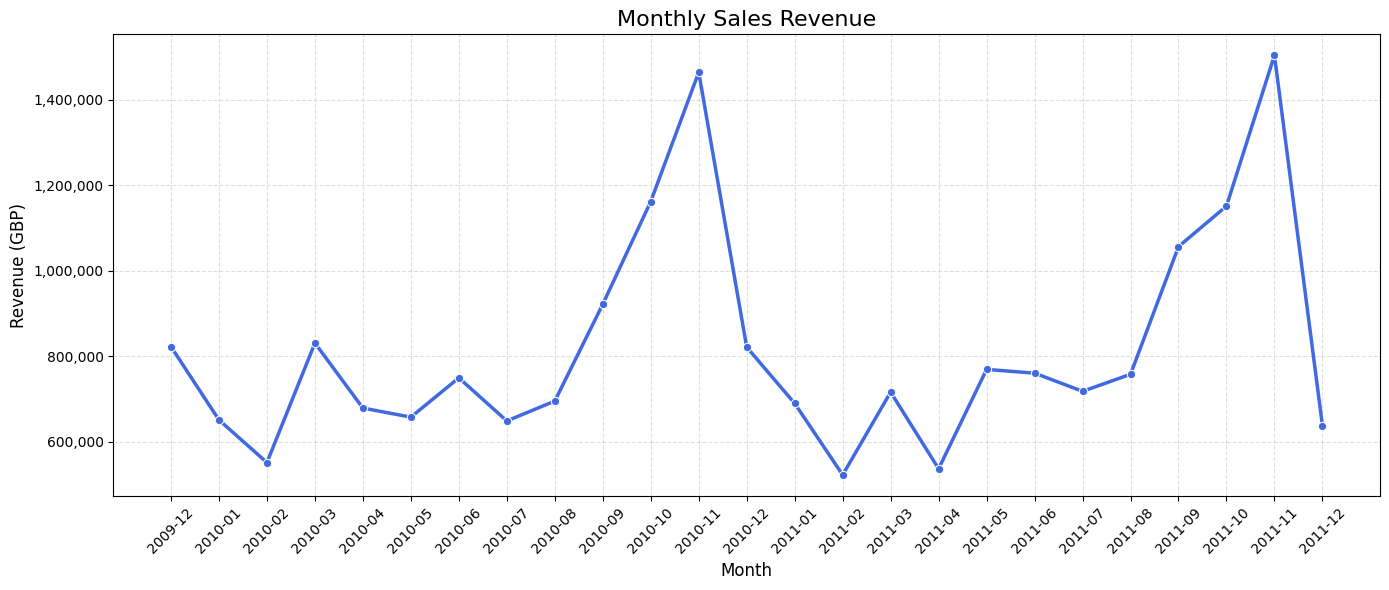

In [ ]:
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=doanh_thu_thang,
    x="Month",
    y="Revenue",
    marker="o",
    linewidth=2.5,
    color="royalblue"
)

plt.title("Monthly Sales Revenue", fontsize=16)
plt.xlabel("Month", fontsize=12)
plt.ylabel("Revenue (GBP)", fontsize=12)

plt.gca().yaxis.set_major_formatter(
    ticker.StrMethodFormatter("{x:,.0f}")
)

plt.xticks(rotation=45)
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()

plt.savefig(
    "/content/bieu_do_1_doanh_thu_thang.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

10.2. Biểu đồ Top 10 sản phẩm có doanh thu cao nhất

---
Sử dụng biểu đồ cột ngang (Horizontal Bar Chart) để so sánh doanh thu của 10 sản phẩm đứng đầu.

Các sản phẩm được xác định dựa trên tổng doanh thu và biểu diễn theo mã sản phẩm. Việc sử dụng mã sản phẩm giúp nhãn trên biểu đồ ngắn gọn, dễ quan sát và tránh nhầm lẫn khi tên sản phẩm quá dài.


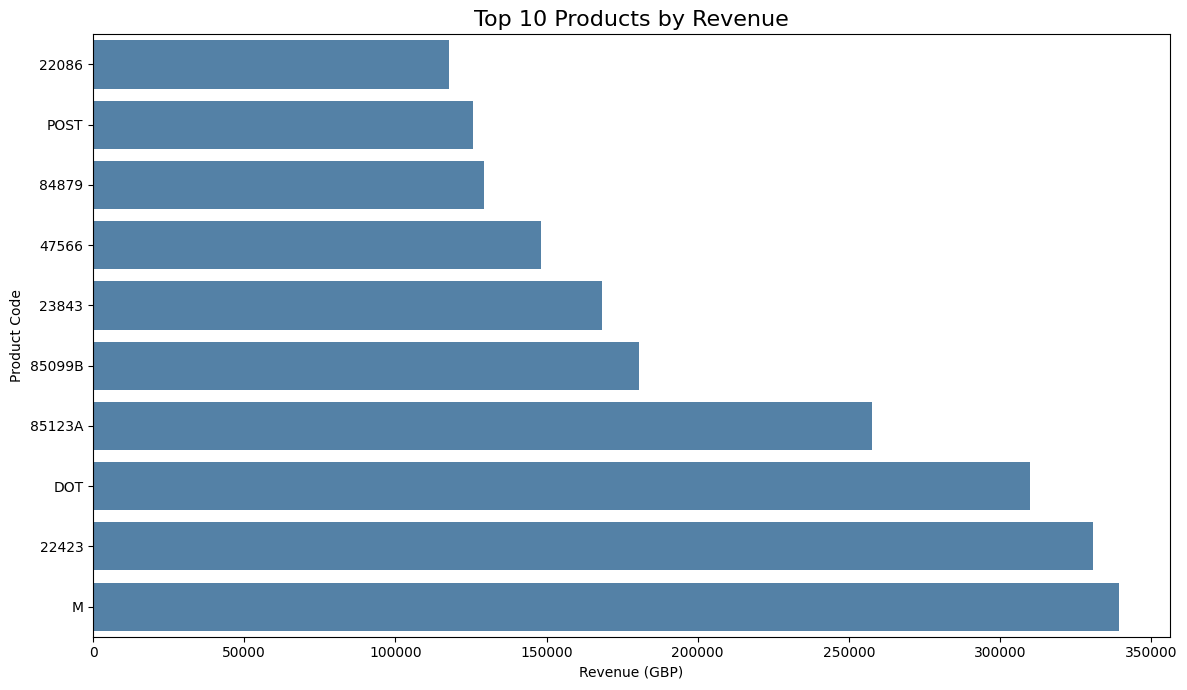

In [ ]:
du_lieu_sp = top10_doanh_thu.sort_values(
    "Tong_doanh_thu",
    ascending=True
).copy()

du_lieu_sp["StockCode"] = (
    du_lieu_sp["StockCode"].astype(str)
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=du_lieu_sp,
    x="Tong_doanh_thu",
    y="StockCode",
    color="steelblue"
)

plt.title("Top 10 Products by Revenue", fontsize=16)
plt.xlabel("Revenue (GBP)")
plt.ylabel("Product Code")
plt.tight_layout()

plt.savefig("/content/bieu_do_2_san_pham.png", dpi=300)
plt.show()

10.3. Biểu đồ Top 10 khách hàng có doanh thu cao nhất

---
Sử dụng biểu đồ cột (Bar Chart) để so sánh tổng giá trị mua hàng của 10 khách hàng có doanh thu cao nhất.

Biểu đồ cho phép xác định mức độ chênh lệch về đóng góp doanh thu giữa các khách hàng, đồng thời hỗ trợ nhận diện nhóm khách hàng có giá trị mua hàng lớn.


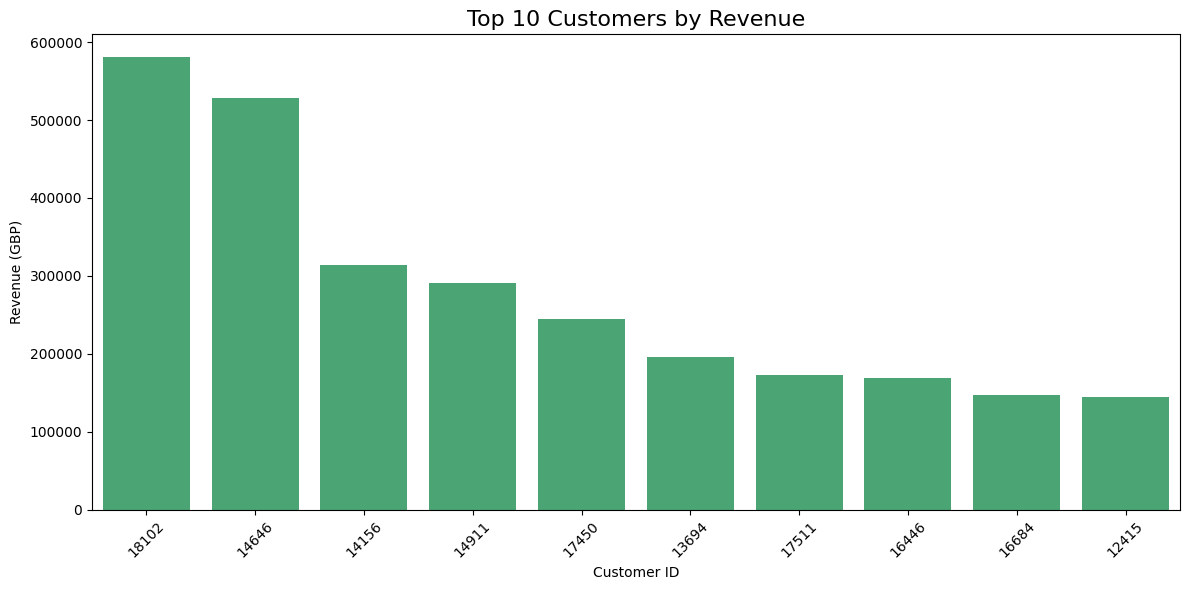

In [ ]:
du_lieu_kh = top10_khach_hang.copy()

du_lieu_kh["Customer ID"] = (
    du_lieu_kh["Customer ID"].astype(str)
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=du_lieu_kh,
    x="Customer ID",
    y="Tong_doanh_thu",
    color="mediumseagreen"
)

plt.title("Top 10 Customers by Revenue", fontsize=16)
plt.xlabel("Customer ID")
plt.ylabel("Revenue (GBP)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig("/content/bieu_do_3_khach_hang.png", dpi=300)
plt.show()

10.4. Biểu đồ tỷ trọng doanh thu theo quốc gia

---

Sử dụng biểu đồ tròn (Pie Chart) để thể hiện tỷ trọng đóng góp doanh thu của các quốc gia.

Để biểu đồ dễ đọc, đề tài biểu diễn 5 quốc gia có doanh thu cao nhất và gộp những quốc gia còn lại thành nhóm "Others".

Biểu đồ giúp đánh giá mức độ tập trung doanh thu ở các thị trường chính.

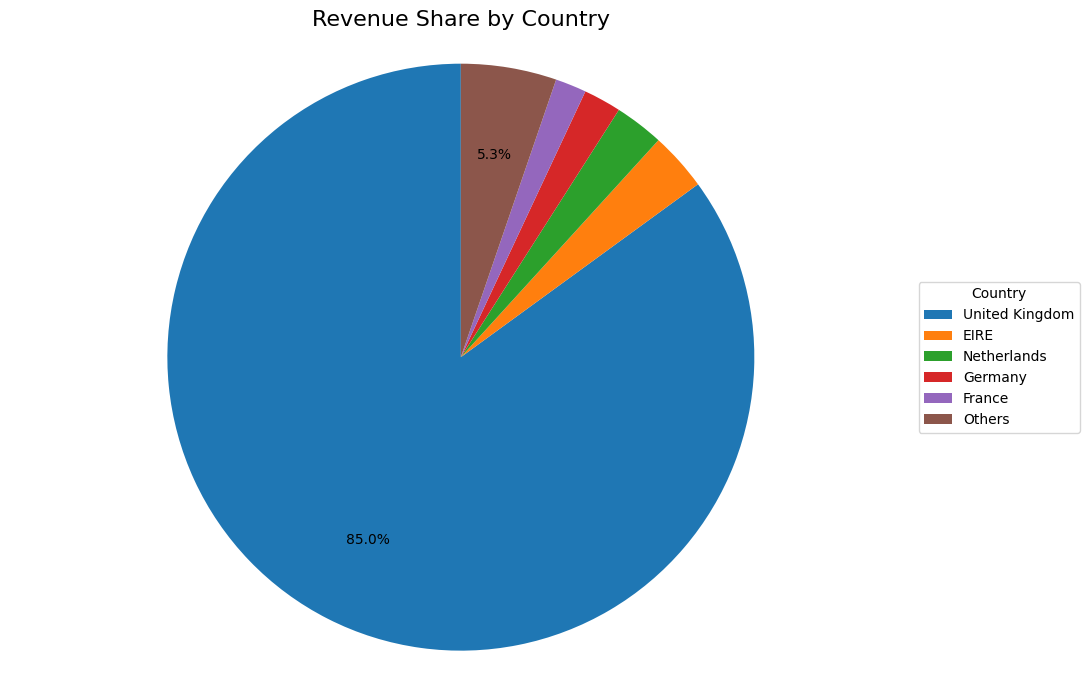

In [ ]:
top5 = quoc_gia.head(5).copy()
doanh_thu_khac = quoc_gia.iloc[5:]["Tong_doanh_thu"].sum()
labels = top5["Country"].tolist()
values = top5["Tong_doanh_thu"].tolist()

if doanh_thu_khac > 0:
    labels.append("Others")
    values.append(doanh_thu_khac)

plt.figure(figsize=(11, 7))

wedges, texts, autotexts = plt.pie(
    values,
    labels=None,
    autopct=lambda pct: f"{pct:.1f}%" if pct >= 5 else "",
    startangle=90,
    pctdistance=0.7
)
plt.legend(
    wedges,
    labels,
    title="Country",
    loc="center left",
    bbox_to_anchor=(1, 0.5)
)

plt.title("Revenue Share by Country", fontsize=16)
plt.axis("equal")
plt.tight_layout()
plt.savefig(
    "/content/bieu_do_4_quoc_gia.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

10.5. Biểu đồ phân bố số lượng sản phẩm

---

Sử dụng biểu đồ Histogram để quan sát sự phân bố của thuộc tính Quantity, tức số lượng sản phẩm trong từng dòng giao dịch.

Do dữ liệu có thể xuất hiện một số giao dịch với số lượng rất lớn, biểu đồ chỉ hiển thị các giá trị không vượt quá phân vị 99% nhằm giúp quan sát rõ hơn nhóm giao dịch phổ biến.

Việc giới hạn giá trị chỉ áp dụng khi vẽ biểu đồ, không làm thay đổi tập dữ liệu đã làm sạch.

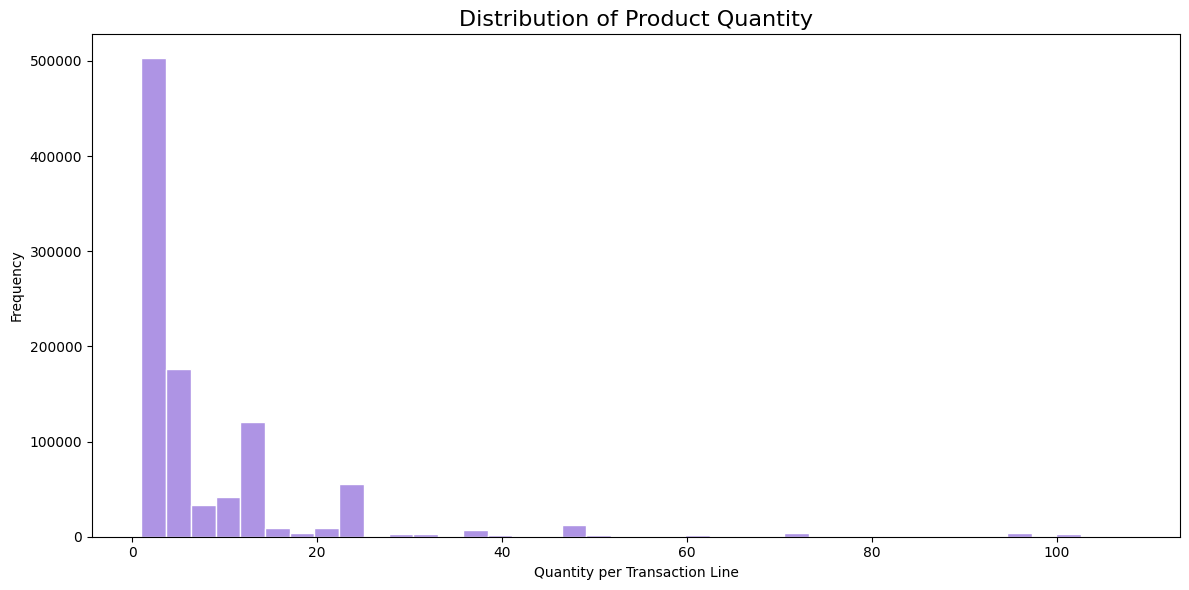

Giới hạn hiển thị (phân vị 99%): 108.0


In [ ]:
gioi_han = df_clean["Quantity"].quantile(0.99)

quantity_plot = df_clean.loc[
    df_clean["Quantity"] <= gioi_han,
    "Quantity"
]

plt.figure(figsize=(12, 6))

sns.histplot(
    quantity_plot,
    bins=40,
    color="mediumpurple",
    edgecolor="white"
)

plt.title("Distribution of Product Quantity", fontsize=16)
plt.xlabel("Quantity per Transaction Line")
plt.ylabel("Frequency")

plt.tight_layout()

plt.savefig("/content/bieu_do_5_so_luong.png", dpi=300)
plt.show()

print("Giới hạn hiển thị (phân vị 99%):", gioi_han)

# **11. Nhận xét**

**11.1. Nhận xét 1: Doanh thu tăng mạnh vào những tháng cuối năm**

---

Dựa trên kết quả phân tích doanh thu theo tháng, hai tháng có doanh thu cao nhất là:

Tháng 11/2011: 1.503.866,78 GBP.

Tháng 11/2010: 1.464.293,14 GBP.

Ngoài ra, tháng 10/2010 đạt 1.161.902,22 GBP và tháng 10/2011 đạt 1.151.263,73 GBP. Điều này cho thấy doanh thu có xu hướng tăng mạnh trong giai đoạn tháng 10 và tháng 11 ở cả hai năm.

Ý nghĩa: Kết quả gợi ý rằng nhu cầu mua sắm có thể gia tăng vào giai đoạn cuối năm. Doanh nghiệp có thể cân nhắc chuẩn bị nguồn hàng, kế hoạch tồn kho và hoạt động tiếp thị trước những tháng có doanh thu cao.

Tuy nhiên, đây mới là xu hướng quan sát được từ dữ liệu. Cần có thêm thông tin về chương trình khuyến mãi, nhu cầu thị trường và các yếu tố khác để xác định nguyên nhân thực sự.

**11.2. Nhận xét 2: Một số mã hàng và khoản thu đóng góp doanh thu nổi bật**

---

Kết quả phân tích cho thấy 5 mã có doanh thu cao nhất bao gồm:

1. M – Manual: 339.226,24 GBP.

2. 22423 – REGENCY CAKESTAND 3 TIER: 330.590,32 GBP.

3. DOT – DOTCOM POSTAGE: 309.854,11 GBP.

4. 85123A – WHITE HANGING HEART T-LIGHT HOLDER: 257.724,71 GBP.

5. 85099B – JUMBO BAG RED WHITE SPOTTY: 180.569,34 GBP.

Trong đó, mã M – Manual có doanh thu cao nhất với 339.226,24 GBP, tiếp theo là sản phẩm REGENCY CAKESTAND 3 TIER với 330.590,32 GBP. Mã DOT – DOTCOM POSTAGE cũng ghi nhận doanh thu đáng kể, đạt 309.854,11 GBP.

Kết quả cho thấy doanh thu từ các dòng giao dịch không chỉ đến từ hàng hóa mà còn bao gồm những khoản thu liên quan đến quá trình bán hàng, chẳng hạn như phí vận chuyển và các khoản ghi nhận thủ công.

Ý nghĩa đối với doanh nghiệp:

Doanh nghiệp nên ưu tiên theo dõi và quản lý nguồn cung của những sản phẩm có doanh thu cao như REGENCY CAKESTAND 3 TIER, WHITE HANGING HEART T-LIGHT HOLDER và JUMBO BAG RED WHITE SPOTTY nhằm hạn chế tình trạng thiếu hàng khi nhu cầu tăng.

Bên cạnh đó, doanh thu đáng kể từ mã DOT – DOTCOM POSTAGE cho thấy các khoản phí liên quan đến vận chuyển cũng có ảnh hưởng đến tổng giá trị giao dịch. Doanh nghiệp nên theo dõi riêng khoản thu này để đánh giá chính sách phí vận chuyển và hiệu quả hoạt động giao hàng.

Đối với mã M – Manual, doanh nghiệp cần kiểm tra và phân loại rõ nội dung các khoản ghi nhận thủ công nhằm tăng tính minh bạch và chính xác trong quản lý doanh thu.

Nhìn chung, kết quả phân tích giúp doanh nghiệp xác định các nguồn đóng góp doanh thu nổi bật, hỗ trợ quản lý danh mục sản phẩm, kiểm soát các khoản thu và xây dựng kế hoạch kinh doanh phù hợp hơn.

**11.3. Nhận xét 3: Một số khách hàng đóng góp doanh thu rất lớn**

---



Dựa trên kết quả phân tích khách hàng, những mã khách hàng có tổng giá trị mua
hàng cao nhất bao gồm:
- 18102: 580.987,04 GBP.
- 14646: 528.602,52 GBP.
- 14156: 313.437,62 GBP.
- 14911: 291.420,81 GBP.
- 17450: 244.784,25 GBP.\

Hai khách hàng đứng đầu đều có tổng giá trị mua hàng vượt 500.000 GBP, cao hơn đáng kể so với các khách hàng tiếp theo trong nhóm dẫn đầu.
Ý nghĩa: Một số khách hàng có đóng góp đáng kể vào tổng doanh thu. Doanh nghiệp có thể cân nhắc xây dựng các chính sách chăm sóc riêng cho nhóm khách hàng có giá trị mua hàng lớn, chẳng hạn như ưu đãi theo doanh số hoặc chương trình duy trì quan hệ khách hàng.
Tuy nhiên, giá trị mua hàng lớn chưa đủ để khẳng định khách hàng có mức độ trung thành cao. Để đánh giá chính xác hơn, cần kết hợp thêm các chỉ tiêu như tần suất mua hàng và thời gian giữa các lần mua.

**11.4. Hạn chế của đề tài**

---


1. Một phần dữ liệu thiếu mã khách hàng, ảnh hưởng đến khả năng phân tích đầy đủ
hành vi mua sắm.

2. Các giao dịch hủy, hoàn trả và giá trị âm đã được loại khỏi tập dữ liệu phân tích doanh thu bán hàng, nên kết quả không phản ánh doanh thu kế toán ròng.

3. Một số mã giao dịch như M và DOT liên quan đến khoản ghi nhận thủ công hoặc phí vận chuyển, không hoàn toàn đại diện cho sản phẩm hàng hóa.

4. Dữ liệu thuộc giai đoạn 2009–2011 nên không thể đại diện cho tình hình thương mại điện tử hiện tại.

5. Một số tháng không có dữ liệu đầy đủ, ảnh hưởng đến việc so sánh doanh thu theo thời gian.


**11.5. Kết luận chung**

---
Đề tài đã ứng dụng Python cùng các thư viện Pandas, NumPy, Matplotlib và Seaborn để thực hiện quá trình khám phá, làm sạch, phân tích và trực quan hóa dữ liệu bán hàng trực tuyến từ bộ dữ liệu Online Retail II.

Từ 1.067.371 dòng dữ liệu ban đầu, sau khi làm sạch còn 1.007.913 dòng, được sử dụng để phân tích hoạt động bán hàng.

Kết quả phân tích cho thấy doanh thu tăng mạnh vào giai đoạn cuối năm, một số mã sản phẩm và khoản thu có đóng góp nổi bật, đồng thời việc thống kê và trực quan hóa dữ liệu có thể hỗ trợ doanh nghiệp trong quá trình đánh giá hiệu quả kinh doanh.

Trong tương lai, đề tài có thể được mở rộng bằng cách phân tích hành vi mua hàng, phân khúc khách hàng và xây dựng mô hình dự báo doanh thu.
